In [1]:
!pip install ultralytics opencv-python matplotlib pandas numpy seaborn nltk transformers torch scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 37.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from ultralytics import YOLO
from google.colab import files
from collections import Counter
from datetime import datetime

print("All libraries imported successfully")
print("GPU Available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully
GPU Available: True


In [3]:
import torch

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

GPU Name: Tesla T4


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Project/archive (2).zip"

extract_path = "/content/PPE_Dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
import os

folder = "/content/drive/MyDrive/Project"

print(os.listdir(folder))

['DashExplain.ipynb', 'Untitled0.ipynb', 'DashExplain_Colab.ipynb', 'archive (2).zip', 'Al-Based Worker Safety Monitoring.ipynb']


In [7]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Project/archive (2).zip"

extract_path = "/content/PPE_Dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [8]:
print(os.listdir(extract_path))         #Verify extraction

['source_files', 'css-data', 'results_yolov8n_100e']


In [9]:
for root, dirs, file_list in os.walk(extract_path):

    level = root.replace(extract_path, '').count(os.sep)

    if level <= 2:

        print("  " * level + os.path.basename(root) + "/")

        for file in file_list[:5]:

            print("  " * (level + 1) + file)

PPE_Dataset/
  source_files/
    source_files/
      portrait-of-woman-with-mask-and-man-with-safety-glasses-on-a-construction-HX01FH.jpg
      schupan_japan1web.jpg
      images.jfif
      indianworkers.mp4
      construction-safety.jpg
  css-data/
    README.dataset.txt
    README.roboflow.txt
    test/
    train/
    valid/
  results_yolov8n_100e/
    kaggle/


In [10]:
yaml_files = []

for root, dirs, file_list in os.walk(extract_path):

    for file in file_list:

        if file.endswith((".yaml", ".yml")):

            yaml_files.append(os.path.join(root, file))

print("YAML files found:")

for file in yaml_files:

    print(file)

YAML files found:
/content/PPE_Dataset/results_yolov8n_100e/kaggle/working/ppe_data.yaml
/content/PPE_Dataset/results_yolov8n_100e/kaggle/working/runs/detect/train/args.yaml


In [11]:
import yaml

yaml_path = "/content/PPE_Dataset/results_yolov8n_100e/kaggle/working/ppe_data.yaml"

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

print(data)

{'names': ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle'], 'nc': 10, 'test': '/kaggle/input/construction-site-safety-image-dataset-roboflow/test', 'train': '/kaggle/input/construction-site-safety-image-dataset-roboflow/train', 'val': '/kaggle/input/construction-site-safety-image-dataset-roboflow/valid'}


In [12]:
import os

dataset_path = "/content/PPE_Dataset/css-data"

for folder in ["train", "valid", "test"]:
    print(folder, ":", os.listdir(os.path.join(dataset_path, folder))[:10])

train : ['images', 'labels']
valid : ['images', 'labels']
test : ['images', 'labels']


In [13]:
import yaml

yaml_path = "/content/PPE_Dataset/results_yolov8n_100e/kaggle/working/ppe_data.yaml"

data = {
    "path": "/content/PPE_Dataset/css-data",
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 10,
    "names": [
        "Hardhat",
        "Mask",
        "NO-Hardhat",
        "NO-Mask",
        "NO-Safety Vest",
        "Person",
        "Safety Cone",
        "Safety Vest",
        "machinery",
        "vehicle"
    ]
}

with open(yaml_path, "w") as file:
    yaml.dump(data, file, sort_keys=False)

print("Dataset YAML paths updated successfully!")

Dataset YAML paths updated successfully!


In [14]:
import os

dataset_path = "/content/PPE_Dataset/css-data"

for folder in ["train", "valid", "test"]:
    image_path = os.path.join(dataset_path, folder, "images")
    label_path = os.path.join(dataset_path, folder, "labels")

    print("\n", folder.upper())
    print("Images:", len(os.listdir(image_path)))
    print("Labels:", len(os.listdir(label_path)))


 TRAIN
Images: 2605
Labels: 2605

 VALID
Images: 114
Labels: 114

 TEST
Images: 82
Labels: 82


In [15]:
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


In [16]:
DATA_YAML = "/content/PPE_Dataset/results_yolov8n_100e/kaggle/working/ppe_data.yaml"

print("Dataset configuration:", DATA_YAML)

Dataset configuration: /content/PPE_Dataset/results_yolov8n_100e/kaggle/working/ppe_data.yaml


In [18]:
# Check if DATA_YAML variable is defined in the global namespace before running
if 'DATA_YAML' not in globals():
    print(" Training halted: 'DATA_YAML' is not defined.")
    print("Please upload 'archive (2).zip', run the extraction cell (xtbMFYUf2Ia7), and the YAML setup cell (zgR2np7V2Ip0) first!")
else:
    results = model.train(
        data=DATA_YAML,
        epochs=15,
        imgsz=512,
        batch=16,
        device=0 if torch.cuda.is_available() else "cpu",
        project="Worker_Safety",
        name="PPE_Detection",
        patience=10
    )
    print("Model training completed!")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PPE_Dataset/results_yolov8n_100e/kaggle/working/ppe_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=PPE_Detection-2, 

In [19]:
import os

for root, dirs, files in os.walk("/content"):
    if "best.pt" in files:
        print("Found best.pt:", os.path.join(root, "best.pt"))

Found best.pt: /content/PPE_Dataset/results_yolov8n_100e/kaggle/working/runs/detect/train/weights/best.pt
Found best.pt: /content/runs/detect/Worker_Safety/PPE_Detection-2/weights/best.pt
Found best.pt: /content/runs/detect/Worker_Safety/PPE_Detection/weights/best.pt


In [20]:
import os
from ultralytics import YOLO

weights_path = "/content/runs/detect/Worker_Safety/PPE_Detection-2/weights/best.pt"

if os.path.exists(weights_path):
    best_model = YOLO(weights_path)
    print("Trained YOLO model loaded successfully!")
else:
    print("Trained weights file not found!")

Trained YOLO model loaded successfully!


In [21]:
# Check if the required variables are defined before running validation
if 'best_model' not in globals():
    print(" Validation halted: 'best_model' is not defined.")
    print("Please complete the model training step successfully before validating.")
elif 'DATA_YAML' not in globals():
    print("Validation halted: 'DATA_YAML' is not defined.")
    print("Please ensure the dataset configuration has been successfully loaded.")
else:
    metrics = best_model.val(
        data=DATA_YAML,
        imgsz=640
    )
    print("Precision:", metrics.box.mp)
    print("Recall:", metrics.box.mr)
    print("mAP50:", metrics.box.map50)
    print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2192.1±434.6 MB/s, size: 59.5 KB)
val: Scanning /content/PPE_Dataset/css-data/valid/labels.cache... 114 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 114/114 36.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.4it/s 3.4s
                   all        114        697      0.803      0.624      0.692       0.36
               Hardhat         42         79      0.866      0.737      0.808      0.492
                  Mask         19         21      0.879       0.81      0.805      0.535
            NO-Hardhat         37         69      0.774      0.545      0.567       0.25
               NO-Mask         44         74      0.765      0.441       0.51      0.211
        NO-Safety Vest         56   

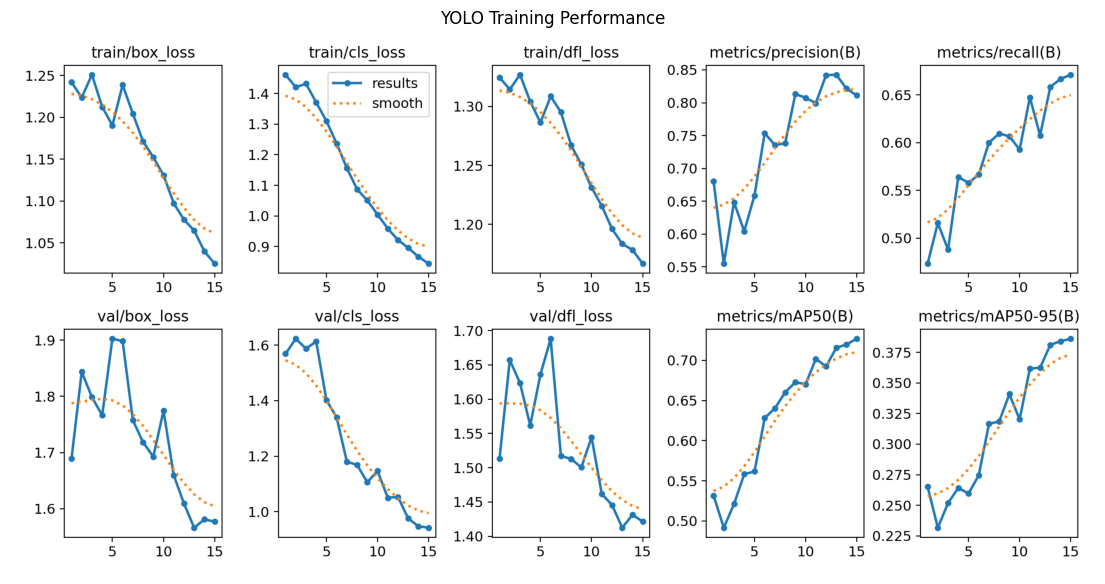

In [22]:
import os
import cv2
import matplotlib.pyplot as plt

results_path = "/content/runs/detect/Worker_Safety/PPE_Detection-2/results.png"

img = cv2.imread(results_path)

if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(14, 8))
    plt.imshow(img)
    plt.title("YOLO Training Performance")
    plt.axis("off")
    plt.show()

else:
    print("Training graph not found.")

In [23]:
from google.colab import files

uploaded_image = files.upload()

image_path = list(uploaded_image.keys())[0]

print("Image uploaded:", image_path)

Saving worker.jpg to worker.jpg
Image uploaded: worker.jpg



image 1/1 /content/worker.jpg: 352x512 4 Hardhats, 3 NO-Masks, 5 Persons, 4 Safety Vests, 6.9ms
Speed: 1.5ms preprocess, 6.9ms inference, 1.7ms postprocess per image at shape (1, 3, 352, 512)
Results saved to /content/runs/detect/predict


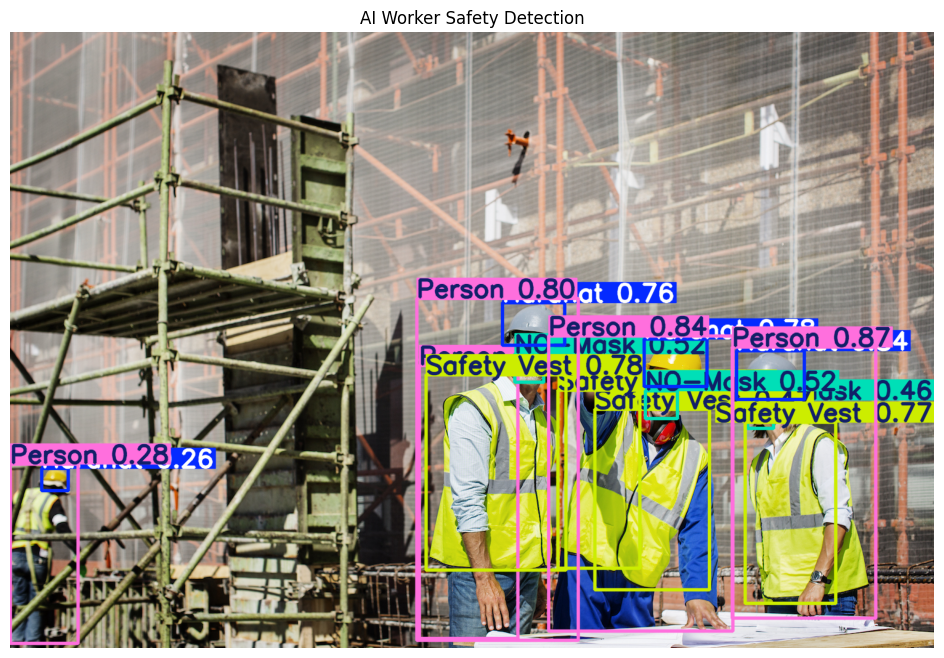

In [41]:
results = best_model.predict(

    source=image_path,

    conf=0.25,

    save=True

)

result = results[0]

annotated_image = result.plot()

plt.figure(figsize=(12, 8))

plt.imshow(
    cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
)

plt.title("AI Worker Safety Detection")

plt.axis("off")

plt.show()


image 1/1 /content/worker.jpg: 352x512 3 Hardhats, 3 NO-Masks, 3 Persons, 4 Safety Vests, 7.5ms
Speed: 1.4ms preprocess, 7.5ms inference, 1.7ms postprocess per image at shape (1, 3, 352, 512)
Results saved to /content/runs/detect/predict


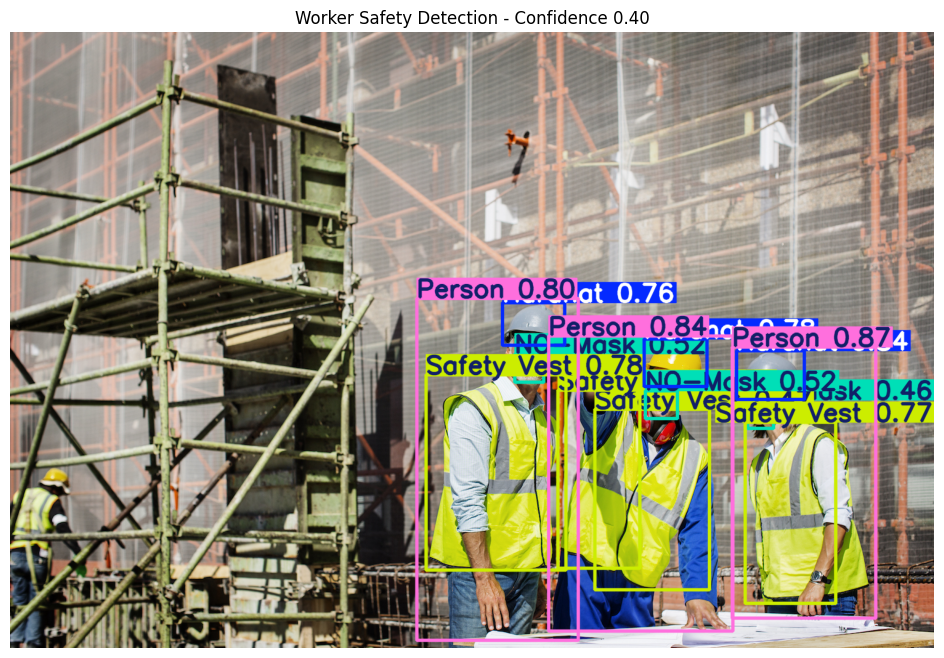

In [45]:
# For better understanding

results = best_model.predict(
    source=image_path,
    conf=0.40,
    save=True
)

result = results[0]
annotated_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(
    cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
)
plt.title("Worker Safety Detection - Confidence 0.40")
plt.axis("off")
plt.show()

In [46]:
from collections import Counter

class_names = best_model.names

detected_classes = []

for box in result.boxes:

    class_id = int(box.cls[0])

    class_name = class_names[class_id]

    detected_classes.append(class_name)

counts = Counter(detected_classes)

print("Detected Objects:")

for name, count in counts.items():

    print(name, ":", count)

Detected Objects:
Person : 3
Hardhat : 3
Safety Vest : 4
NO-Mask : 3


In [47]:
# checks whether the model detected missing personal protective equipment (PPE)

def normalize_name(name):
    return (
        name.lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )


no_helmet_labels = [
    "nohelmet",
    "nohardhat"
]

no_vest_labels = [
    "novest",
    "nosafetyvest"
]

no_mask_labels = [
    "nomask"
]

normalized_classes = [
    normalize_name(name)
    for name in detected_classes
]

helmet_missing = any(
    name in no_helmet_labels
    for name in normalized_classes
)

vest_missing = any(
    name in no_vest_labels
    for name in normalized_classes
)

mask_missing = any(
    name in no_mask_labels
    for name in normalized_classes
)

if helmet_missing:
    print("WARNING: Helmet violation detected!")

if vest_missing:
    print("WARNING: Safety vest violation detected!")

if mask_missing:
    print("WARNING: Mask violation detected!")

if not helmet_missing and not vest_missing and not mask_missing:
    print("No missing PPE classes detected.")

In [49]:
# It will evaluate  model on the test dataset and keep the results separate from validation.

test_metrics = best_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640
)

print("\nFINAL TEST RESULTS")
print("------------------")
print("Precision:", round(test_metrics.box.mp, 3))
print("Recall:", round(test_metrics.box.mr, 3))
print("mAP50:", round(test_metrics.box.map50, 3))
print("mAP50-95:", round(test_metrics.box.map, 3))

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1512.5±627.9 MB/s, size: 63.7 KB)
val: Scanning /content/PPE_Dataset/css-data/test/labels.cache... 82 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 82/82 24.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.0it/s 6.0s
                   all         82        760      0.745      0.623      0.659      0.317
               Hardhat         30        110      0.911      0.773       0.85      0.504
                  Mask         16         28      0.912      0.745      0.787      0.397
            NO-Hardhat         25         41      0.747      0.537      0.481       0.19
               NO-Mask         30         79      0.651      0.519      0.599      0.212
        NO-Safety Vest         36        

In [50]:

import os
from pathlib import Path

# Find all trained best.pt model files
models = list(Path("/content").rglob("best.pt"))

print("Available trained models:")

for model in models:
    print(model)


Available trained models:
/content/runs/detect/Worker_Safety/PPE_Detection/weights/best.pt
/content/runs/detect/Worker_Safety/PPE_Detection-2/weights/best.pt
/content/PPE_Dataset/results_yolov8n_100e/kaggle/working/runs/detect/train/weights/best.pt


In [51]:

from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded image:", image_path)


Saving worker.jpg to worker (1).jpg
Uploaded image: worker (1).jpg



image 1/1 /content/worker (1).jpg: 352x512 4 Hardhats, 3 NO-Masks, 5 Persons, 4 Safety Vests, 6.1ms
Speed: 1.6ms preprocess, 6.1ms inference, 1.3ms postprocess per image at shape (1, 3, 352, 512)
Results saved to /content/runs/detect/predict-2


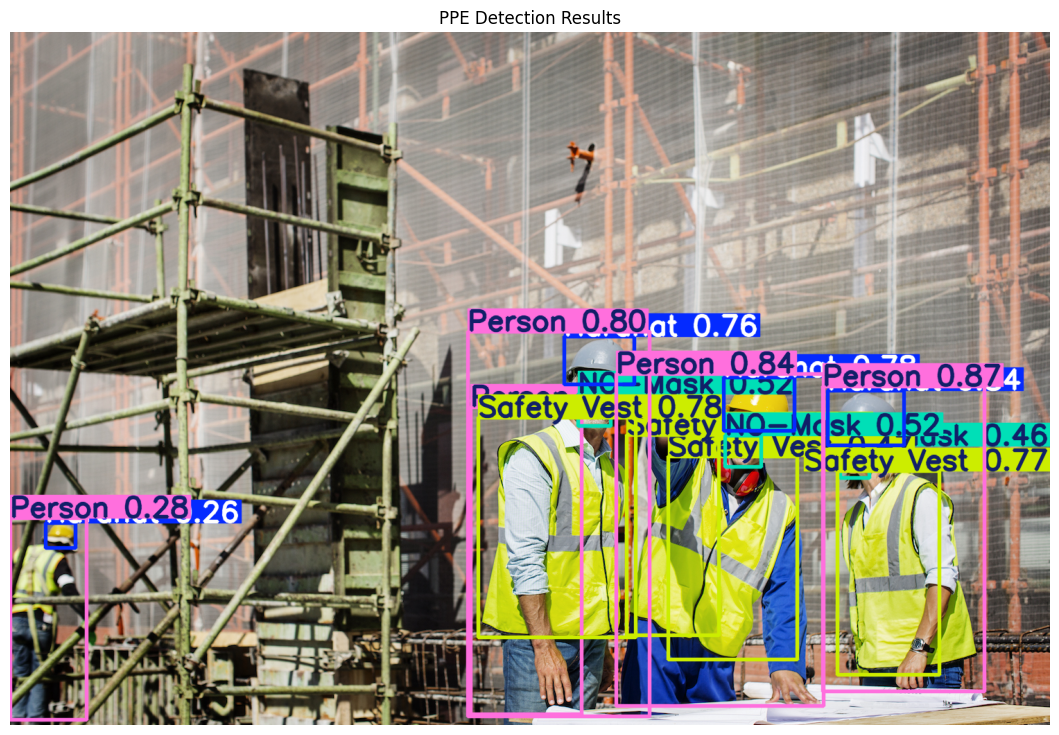

Detection completed!


In [53]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load our selected trained model
model = YOLO(
    "/content/runs/detect/Worker_Safety/PPE_Detection-2/weights/best.pt"
)

# Detect PPE
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

# Display detected image
output = results[0].plot()

plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("PPE Detection Results")
plt.show()

print("Detection completed!")
